In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("retail_sales_customer_analytics.csv")

In [3]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,Quantity,Unit_Price,Discount,Sales,Cost,Profit,Sales_Channel
0,O00001,2025-01-28,C0227,Customer 227,Home Office,Hyderabad,North,P036,Product 36,Electronics,5,30276.66,0.05,143814.13,112669.94,31144.19,Online
1,O00002,2025-02-04,C0244,Customer 244,Consumer,Chennai,South,P013,Product 13,Furniture,5,6152.23,0.20,24608.92,20325.68,4283.24,Online
2,O00003,2025-05-05,C0491,Customer 491,Consumer,Jaipur,South,P032,Product 32,Clothing,4,2634.21,0.05,10010.00,5445.37,4564.63,Marketplace
3,O00004,2025-11-17,C0337,Customer 337,Home Office,Pune,South,P036,Product 36,Electronics,1,30276.66,0.05,28762.83,21958.43,6804.40,Marketplace
4,O00005,2025-02-11,C0446,Customer 446,Home Office,Delhi,East,P037,Product 37,Furniture,5,12493.85,0.30,43728.48,40618.59,3109.89,Marketplace


In [4]:
df.shape

(5000, 17)

In [5]:
df.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Segment',
       'City', 'Region', 'Product_ID', 'Product_Name', 'Category', 'Quantity',
       'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Sales_Channel'],
      dtype='str')

In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       5000 non-null   str    
 1   Order_Date     5000 non-null   str    
 2   Customer_ID    5000 non-null   str    
 3   Customer_Name  5000 non-null   str    
 4   Segment        5000 non-null   str    
 5   City           5000 non-null   str    
 6   Region         5000 non-null   str    
 7   Product_ID     5000 non-null   str    
 8   Product_Name   5000 non-null   str    
 9   Category       5000 non-null   str    
 10  Quantity       5000 non-null   int64  
 11  Unit_Price     5000 non-null   float64
 12  Discount       4975 non-null   float64
 13  Sales          5000 non-null   float64
 14  Cost           5000 non-null   float64
 15  Profit         5000 non-null   float64
 16  Sales_Channel  4985 non-null   str    
dtypes: float64(5), int64(1), str(11)
memory usage: 664.2 KB


In [7]:
df.isnull().sum()

Order_ID          0
Order_Date        0
Customer_ID       0
Customer_Name     0
Segment           0
City              0
Region            0
Product_ID        0
Product_Name      0
Category          0
Quantity          0
Unit_Price        0
Discount         25
Sales             0
Cost              0
Profit            0
Sales_Channel    15
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df["Order_Date"] = pd.to_datetime(df["Order_Date"])

In [10]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 17 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       5000 non-null   str           
 1   Order_Date     5000 non-null   datetime64[us]
 2   Customer_ID    5000 non-null   str           
 3   Customer_Name  5000 non-null   str           
 4   Segment        5000 non-null   str           
 5   City           5000 non-null   str           
 6   Region         5000 non-null   str           
 7   Product_ID     5000 non-null   str           
 8   Product_Name   5000 non-null   str           
 9   Category       5000 non-null   str           
 10  Quantity       5000 non-null   int64         
 11  Unit_Price     5000 non-null   float64       
 12  Discount       4975 non-null   float64       
 13  Sales          5000 non-null   float64       
 14  Cost           5000 non-null   float64       
 15  Profit         5000 non-null   f

In [11]:
df["Year"] = df["Order_Date"].dt.year

In [12]:
df["Month"] = df["Order_Date"].dt.month

In [13]:
df["Month_Name"] = df["Order_Date"].dt.month_name()

In [14]:
df["Quarter"] = df["Order_Date"].dt.quarter

In [15]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,...,Unit_Price,Discount,Sales,Cost,Profit,Sales_Channel,Year,Month,Month_Name,Quarter
0,O00001,2025-01-28,C0227,Customer 227,Home Office,Hyderabad,North,P036,Product 36,Electronics,...,30276.66,0.05,143814.13,112669.94,31144.19,Online,2025,1,January,1
1,O00002,2025-02-04,C0244,Customer 244,Consumer,Chennai,South,P013,Product 13,Furniture,...,6152.23,0.20,24608.92,20325.68,4283.24,Online,2025,2,February,1
2,O00003,2025-05-05,C0491,Customer 491,Consumer,Jaipur,South,P032,Product 32,Clothing,...,2634.21,0.05,10010.00,5445.37,4564.63,Marketplace,2025,5,May,2
3,O00004,2025-11-17,C0337,Customer 337,Home Office,Pune,South,P036,Product 36,Electronics,...,30276.66,0.05,28762.83,21958.43,6804.40,Marketplace,2025,11,November,4
4,O00005,2025-02-11,C0446,Customer 446,Home Office,Delhi,East,P037,Product 37,Furniture,...,12493.85,0.30,43728.48,40618.59,3109.89,Marketplace,2025,2,February,1


In [16]:
df.groupby("Region")["Sales"].sum()

Region
East     8.621339e+07
North    1.175511e+08
South    1.110127e+08
West     9.626977e+07
Name: Sales, dtype: float64

In [17]:
df.groupby("Category")["Profit"].sum().sort_values(ascending = False)

Category
Office Supplies    36828004.47
Home & Kitchen     26415352.27
Clothing           22207797.57
Furniture          21768092.73
Electronics        10697710.80
Name: Profit, dtype: float64

In [18]:
df.groupby("Product_Name")["Sales"].sum().sort_values(ascending = False).head(5)

Product_Name
Product 18    18847944.63
Product 23    17932445.99
Product 28    17619175.98
Product 7     17093308.27
Product 12    17084132.77
Name: Sales, dtype: float64

In [19]:
df.groupby("Region")["Profit"].mean().sort_values(ascending = False)

Region
North    24258.415072
East     23819.937275
West     23310.980663
South    22962.716457
Name: Profit, dtype: float64

In [20]:
df.groupby("Category")["Quantity"].sum().sort_values(ascending = False)

Category
Furniture          4638
Office Supplies    4296
Clothing           4279
Home & Kitchen     4274
Electronics        2732
Name: Quantity, dtype: int64

In [21]:
df.groupby("Customer_Name")["Sales"].sum().sort_values(ascending = False).head(10)

Customer_Name
Customer 154    2290468.04
Customer 414    2249808.46
Customer 90     1977786.39
Customer 450    1927526.96
Customer 364    1857890.63
Customer 369    1857402.06
Customer 314    1700518.85
Customer 485    1686485.30
Customer 49     1683309.01
Customer 256    1658379.40
Name: Sales, dtype: float64

In [22]:
df.groupby("Month")["Sales"].sum().sort_index()

Month
1     34353273.74
2     32212763.47
3     40300145.06
4     34583570.55
5     34740668.81
6     31076058.39
7     34795060.44
8     30541168.34
9     35689070.55
10    33108353.63
11    36300241.73
12    33346568.44
Name: Sales, dtype: float64

In [23]:
df.groupby("Month")["Profit"].sum().sort_index()

Month
1      9685229.33
2      9092405.06
3     11492719.79
4      9930274.84
5      9975191.69
6      9135915.51
7      9911540.19
8      8779999.32
9     10392850.02
10     9271204.93
11    10651621.15
12     9598006.01
Name: Profit, dtype: float64

In [24]:
df.groupby("Segment")["Sales"].sum().sort_values(ascending = False)

Segment
Consumer       2.285992e+08
Corporate      1.197046e+08
Home Office    6.274317e+07
Name: Sales, dtype: float64

In [25]:
df[df["Sales"]>100000]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,...,Unit_Price,Discount,Sales,Cost,Profit,Sales_Channel,Year,Month,Month_Name,Quarter
0,O00001,2025-01-28,C0227,Customer 227,Home Office,Hyderabad,North,P036,Product 36,Electronics,...,30276.66,0.05,143814.13,112669.94,31144.19,Online,2025,1,January,1
6,O00007,2025-07-07,C0491,Customer 491,Consumer,Jaipur,North,P022,Product 22,Clothing,...,45030.93,0.15,267934.03,160689.45,107244.58,Store,2025,7,July,3
11,O00012,2025-11-16,C0073,Customer 73,Consumer,Ahmedabad,East,P024,Product 24,Furniture,...,29991.43,0.10,134961.44,98043.12,36918.32,Marketplace,2025,11,November,4
12,O00013,2025-02-10,C0201,Customer 201,Corporate,Ahmedabad,South,P023,Product 23,Furniture,...,43732.34,0.20,174929.36,156820.57,18108.79,Marketplace,2025,2,February,1
13,O00014,2025-08-03,C0296,Customer 296,Consumer,Bangalore,South,P022,Product 22,Clothing,...,45030.93,0.05,256676.30,159376.13,97300.17,Marketplace,2025,8,August,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4981,O04982,2025-04-22,C0296,Customer 296,Consumer,Bangalore,North,P047,Product 47,Electronics,...,36708.83,0.15,187215.03,169074.20,18140.83,Marketplace,2025,4,April,2
4984,O04985,2025-03-13,C0236,Customer 236,Corporate,Jaipur,East,P043,Product 43,Clothing,...,28450.31,0.00,142251.55,81119.54,61132.01,Marketplace,2025,3,March,1
4993,O04994,2025-09-20,C0350,Customer 350,Corporate,Lucknow,North,P018,Product 18,Home & Kitchen,...,41538.17,0.20,132922.14,99977.91,32944.23,Store,2025,9,September,3
4994,O04995,2025-11-18,C0056,Customer 56,Home Office,Hyderabad,East,P024,Product 24,Furniture,...,29991.43,0.15,178449.01,142731.10,35717.91,Store,2025,11,November,4


In [26]:
df[df["Region"] == "North" ]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,...,Unit_Price,Discount,Sales,Cost,Profit,Sales_Channel,Year,Month,Month_Name,Quarter
0,O00001,2025-01-28,C0227,Customer 227,Home Office,Hyderabad,North,P036,Product 36,Electronics,...,30276.66,0.05,143814.13,112669.94,31144.19,Online,2025,1,January,1
5,O00006,2025-03-26,C0365,Customer 365,Home Office,Hyderabad,North,P026,Product 26,Home & Kitchen,...,33352.32,0.10,60034.18,43483.36,16550.82,Store,2025,3,March,1
6,O00007,2025-07-07,C0491,Customer 491,Consumer,Jaipur,North,P022,Product 22,Clothing,...,45030.93,0.15,267934.03,160689.45,107244.58,Store,2025,7,July,3
8,O00009,2025-09-28,C0201,Customer 201,Corporate,Ahmedabad,North,P031,Product 31,Office Supplies,...,26090.21,0.15,44353.36,30366.31,13987.05,Store,2025,9,September,3
10,O00011,2025-04-15,C0450,Customer 450,Consumer,Ahmedabad,North,P038,Product 38,Home & Kitchen,...,19647.99,0.15,83503.96,63149.11,20354.85,Marketplace,2025,4,April,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4988,O04989,2025-08-27,C0395,Customer 395,Consumer,Ahmedabad,North,P037,Product 37,Furniture,...,12493.85,0.05,71214.95,49365.92,21849.03,Store,2025,8,August,3
4989,O04990,2025-09-10,C0110,Customer 110,Consumer,Chennai,North,P004,Product 4,Electronics,...,13117.02,0.00,78702.12,58892.11,19810.01,Online,2025,9,September,3
4991,O04992,2025-10-30,C0392,Customer 392,Consumer,Kolkata,North,P025,Product 25,Electronics,...,30145.69,NaN,85915.22,69311.60,16603.62,Store,2025,10,October,4
4993,O04994,2025-09-20,C0350,Customer 350,Corporate,Lucknow,North,P018,Product 18,Home & Kitchen,...,41538.17,0.20,132922.14,99977.91,32944.23,Store,2025,9,September,3


In [27]:
df[df["Category"] == "Electronics" ]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,...,Unit_Price,Discount,Sales,Cost,Profit,Sales_Channel,Year,Month,Month_Name,Quarter
0,O00001,2025-01-28,C0227,Customer 227,Home Office,Hyderabad,North,P036,Product 36,Electronics,...,30276.66,0.05,143814.13,112669.94,31144.19,Online,2025,1,January,1
3,O00004,2025-11-17,C0337,Customer 337,Home Office,Pune,South,P036,Product 36,Electronics,...,30276.66,0.05,28762.83,21958.43,6804.40,Marketplace,2025,11,November,4
7,O00008,2025-04-21,C0482,Customer 482,Corporate,Lucknow,South,P004,Product 4,Electronics,...,13117.02,0.15,78046.27,61864.51,16181.76,Online,2025,4,April,2
27,O00028,2025-03-11,C0108,Customer 108,Corporate,Mumbai,South,P044,Product 44,Electronics,...,23959.70,0.10,107818.65,80883.81,26934.84,Online,2025,3,March,1
40,O00041,2025-02-17,C0017,Customer 17,Consumer,Chennai,South,P025,Product 25,Electronics,...,30145.69,0.10,27131.12,21262.38,5868.74,Online,2025,2,February,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4964,O04965,2025-01-08,C0364,Customer 364,Consumer,Hyderabad,South,P047,Product 47,Electronics,...,36708.83,0.25,192721.36,176528.68,16192.68,Online,2025,1,January,1
4981,O04982,2025-04-22,C0296,Customer 296,Consumer,Bangalore,North,P047,Product 47,Electronics,...,36708.83,0.15,187215.03,169074.20,18140.83,Marketplace,2025,4,April,2
4987,O04988,2025-08-19,C0360,Customer 360,Corporate,Hyderabad,South,P004,Product 4,Electronics,...,13117.02,0.20,31480.85,29353.94,2126.91,Online,2025,8,August,3
4989,O04990,2025-09-10,C0110,Customer 110,Consumer,Chennai,North,P004,Product 4,Electronics,...,13117.02,0.00,78702.12,58892.11,19810.01,Online,2025,9,September,3


In [28]:
df[df["Discount"] > 0.20 ]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,...,Unit_Price,Discount,Sales,Cost,Profit,Sales_Channel,Year,Month,Month_Name,Quarter
4,O00005,2025-02-11,C0446,Customer 446,Home Office,Delhi,East,P037,Product 37,Furniture,...,12493.85,0.30,43728.48,40618.59,3109.89,Marketplace,2025,2,February,1
9,O00010,2025-11-21,C0154,Customer 154,Consumer,Delhi,West,P018,Product 18,Home & Kitchen,...,41538.17,0.25,93460.88,78360.47,15100.41,Store,2025,11,November,4
15,O00016,2025-02-25,C0129,Customer 129,Consumer,Chennai,South,P031,Product 31,Office Supplies,...,26090.21,0.25,97838.29,78815.56,19022.73,Online,2025,2,February,1
20,O00021,2025-07-10,C0042,Customer 42,Consumer,Bangalore,East,P005,Product 5,Clothing,...,7226.00,0.25,10839.00,8570.34,2268.66,Store,2025,7,July,3
28,O00029,2025-10-20,C0172,Customer 172,Consumer,Bangalore,South,P048,Product 48,Furniture,...,10982.54,0.30,23063.33,23820.88,-757.55,Online,2025,10,October,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4948,O04949,2025-09-30,C0231,Customer 231,Corporate,Hyderabad,West,P036,Product 36,Electronics,...,30276.66,0.25,22707.50,22303.52,403.98,Marketplace,2025,9,September,3
4952,O04953,2025-10-18,C0433,Customer 433,Corporate,Jaipur,East,P009,Product 9,Clothing,...,8832.46,0.30,6182.72,5181.22,1001.50,Store,2025,10,October,4
4964,O04965,2025-01-08,C0364,Customer 364,Consumer,Hyderabad,South,P047,Product 47,Electronics,...,36708.83,0.25,192721.36,176528.68,16192.68,Online,2025,1,January,1
4976,O04977,2025-10-26,C0485,Customer 485,Corporate,Mumbai,South,P022,Product 22,Clothing,...,45030.93,0.25,236412.38,179698.86,56713.52,Store,2025,10,October,4


In [29]:
df[(df["Region"] == "North") & (df["Category"] == "Electronics")]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,...,Unit_Price,Discount,Sales,Cost,Profit,Sales_Channel,Year,Month,Month_Name,Quarter
0,O00001,2025-01-28,C0227,Customer 227,Home Office,Hyderabad,North,P036,Product 36,Electronics,...,30276.66,0.05,143814.13,112669.94,31144.19,Online,2025,1,January,1
65,O00066,2025-04-15,C0143,Customer 143,Consumer,Ahmedabad,North,P044,Product 44,Electronics,...,23959.70,0.00,119798.50,87629.18,32169.32,Online,2025,4,April,2
74,O00075,2025-12-06,C0016,Customer 16,Consumer,Mumbai,North,P004,Product 4,Electronics,...,13117.02,0.10,70831.91,61171.78,9660.13,Store,2025,12,December,4
128,O00129,2025-01-01,C0470,Customer 470,Home Office,Mumbai,North,P004,Product 4,Electronics,...,13117.02,0.25,9837.76,9613.27,224.49,Store,2025,1,January,1
132,O00133,2025-01-15,C0161,Customer 161,Consumer,Jaipur,North,P050,Product 50,Electronics,...,13334.52,0.10,48004.27,38266.17,9738.10,Store,2025,1,January,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4880,O04881,2025-07-29,C0166,Customer 166,Corporate,Pune,North,P004,Product 4,Electronics,...,13117.02,0.20,31480.85,28338.40,3142.45,Online,2025,7,July,3
4890,O04891,2025-01-07,C0433,Customer 433,Corporate,Jaipur,North,P036,Product 36,Electronics,...,30276.66,0.05,28762.83,20199.67,8563.16,Marketplace,2025,1,January,1
4981,O04982,2025-04-22,C0296,Customer 296,Consumer,Bangalore,North,P047,Product 47,Electronics,...,36708.83,0.15,187215.03,169074.20,18140.83,Marketplace,2025,4,April,2
4989,O04990,2025-09-10,C0110,Customer 110,Consumer,Chennai,North,P004,Product 4,Electronics,...,13117.02,0.00,78702.12,58892.11,19810.01,Online,2025,9,September,3


In [30]:
df.loc[df["Sales"].idxmax(),["Product_Name" , "Sales"]]

Product_Name    Product 7
Sales           344573.53
Name: 2007, dtype: object

In [31]:
df.loc[df["Sales"].idxmax(),["Customer_Name" , "Sales"]]

Customer_Name    Customer 163
Sales               344573.53
Name: 2007, dtype: object

In [32]:
df.groupby("Region")[["Sales" , "Profit"]].sum()

,Sales,Profit
Region,,
East,8.621339e+07,24653635.08
North,1.175511e+08,33719196.95
South,1.110127e+08,31757436.86
West,9.626977e+07,27786688.95


In [33]:
df[df["Sales_Channel"].isnull()]

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,...,Unit_Price,Discount,Sales,Cost,Profit,Sales_Channel,Year,Month,Month_Name,Quarter
1371,O01372,2025-06-12,C0073,Customer 73,Consumer,Ahmedabad,East,P006,Product 6,Furniture,...,41796.03,0.30,175543.33,160897.24,14646.09,NaN,2025,6,June,2
1422,O01423,2025-01-27,C0092,Customer 92,Corporate,Delhi,North,P034,Product 34,Home & Kitchen,...,36980.27,0.15,125732.92,87523.30,38209.62,NaN,2025,1,January,1
1525,O01526,2025-06-23,C0181,Customer 181,Consumer,Pune,North,P025,Product 25,Electronics,...,30145.69,0.20,144699.31,122752.77,21946.54,NaN,2025,6,June,2
2051,O02052,2025-03-22,C0426,Customer 426,Consumer,Mumbai,East,P007,Product 7,Office Supplies,...,49224.79,0.20,157519.33,105870.25,51649.08,NaN,2025,3,March,1
2221,O02222,2025-08-25,C0220,Customer 220,Corporate,Pune,East,P034,Product 34,Home & Kitchen,...,36980.27,0.25,110940.81,84839.83,26100.98,NaN,2025,8,August,3
2662,O02663,2025-02-18,C0239,Customer 239,Corporate,Ahmedabad,North,P031,Product 31,Office Supplies,...,26090.21,0.00,182631.47,101214.61,81416.86,NaN,2025,2,February,1
2989,O02990,2025-01-14,C0369,Customer 369,Consumer,Lucknow,North,P004,Product 4,Electronics,...,13117.02,0.15,55747.34,47429.45,8317.89,NaN,2025,1,January,1
3196,O03197,2025-06-22,C0377,Customer 377,Corporate,Jaipur,South,P008,Product 8,Office Supplies,...,26426.80,0.30,73995.04,56869.72,17125.32,NaN,2025,6,June,2
3334,O03335,2025-10-01,C0165,Customer 165,Consumer,Bangalore,East,P034,Product 34,Home & Kitchen,...,36980.27,0.05,210787.54,147693.76,63093.78,NaN,2025,10,October,4
3380,O03381,2025-10-17,C0421,Customer 421,Corporate,Bangalore,East,P025,Product 25,Electronics,...,30145.69,0.10,54262.24,42675.57,11586.67,NaN,2025,10,October,4


In [34]:
df["Sales_Channel"] = df["Sales_Channel"].fillna("Unknown")

In [35]:
df["Discount"] = df.groupby("Category")["Discount"].transform(
    lambda x : x.fillna(x.mean())
)

In [36]:
df["Profit_Margin"] = (df["Profit"]/df["Sales"]) * 100

In [37]:
sales = df.copy()

In [38]:
sales.shape

(5000, 22)

In [39]:
sales.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 22 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Order_ID       5000 non-null   str           
 1   Order_Date     5000 non-null   datetime64[us]
 2   Customer_ID    5000 non-null   str           
 3   Customer_Name  5000 non-null   str           
 4   Segment        5000 non-null   str           
 5   City           5000 non-null   str           
 6   Region         5000 non-null   str           
 7   Product_ID     5000 non-null   str           
 8   Product_Name   5000 non-null   str           
 9   Category       5000 non-null   str           
 10  Quantity       5000 non-null   int64         
 11  Unit_Price     5000 non-null   float64       
 12  Discount       5000 non-null   float64       
 13  Sales          5000 non-null   float64       
 14  Cost           5000 non-null   float64       
 15  Profit         5000 non-null   f

In [40]:
sales.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Segment,City,Region,Product_ID,Product_Name,Category,...,Discount,Sales,Cost,Profit,Sales_Channel,Year,Month,Month_Name,Quarter,Profit_Margin
0,O00001,2025-01-28,C0227,Customer 227,Home Office,Hyderabad,North,P036,Product 36,Electronics,...,0.05,143814.13,112669.94,31144.19,Online,2025,1,January,1,21.655862
1,O00002,2025-02-04,C0244,Customer 244,Consumer,Chennai,South,P013,Product 13,Furniture,...,0.20,24608.92,20325.68,4283.24,Online,2025,2,February,1,17.405234
2,O00003,2025-05-05,C0491,Customer 491,Consumer,Jaipur,South,P032,Product 32,Clothing,...,0.05,10010.00,5445.37,4564.63,Marketplace,2025,5,May,2,45.600699
3,O00004,2025-11-17,C0337,Customer 337,Home Office,Pune,South,P036,Product 36,Electronics,...,0.05,28762.83,21958.43,6804.40,Marketplace,2025,11,November,4,23.656921
4,O00005,2025-02-11,C0446,Customer 446,Home Office,Delhi,East,P037,Product 37,Furniture,...,0.30,43728.48,40618.59,3109.89,Marketplace,2025,2,February,1,7.111818


In [41]:
sales.columns

Index(['Order_ID', 'Order_Date', 'Customer_ID', 'Customer_Name', 'Segment',
       'City', 'Region', 'Product_ID', 'Product_Name', 'Category', 'Quantity',
       'Unit_Price', 'Discount', 'Sales', 'Cost', 'Profit', 'Sales_Channel',
       'Year', 'Month', 'Month_Name', 'Quarter', 'Profit_Margin'],
      dtype='str')

In [42]:
sales.isnull().sum()

Order_ID         0
Order_Date       0
Customer_ID      0
Customer_Name    0
Segment          0
City             0
Region           0
Product_ID       0
Product_Name     0
Category         0
Quantity         0
Unit_Price       0
Discount         0
Sales            0
Cost             0
Profit           0
Sales_Channel    0
Year             0
Month            0
Month_Name       0
Quarter          0
Profit_Margin    0
dtype: int64

In [43]:
sales.duplicated().sum()

np.int64(0)

In [44]:
Total_Sales = sales["Sales"].sum()

In [45]:
Total_Profit = sales["Profit"].sum()

In [46]:
Total_Quantity = sales["Quantity"].sum()

In [47]:
Avg_Order_Value = sales["Sales"].mean()

In [48]:
sales["Profit_Margin"] = (sales["Profit"] / sales["Sales"]) *100

In [49]:
sales["Profit_Margin"].describe()

count    5000.000000
mean       28.373380
std        10.087083
min       -10.396539
25%        21.695871
50%        29.391466
75%        35.991884
max        49.316549
Name: Profit_Margin, dtype: float64

In [50]:
regional_analysis = sales.groupby("Region").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum")
).sort_values("Total_Sales", ascending=False)

regional_analysis

,Total_Sales,Total_Profit,Total_Quantity
Region,,,
North,1.175511e+08,33719196.95,5702
South,1.110127e+08,31757436.86,5568
West,9.626977e+07,27786688.95,4712
East,8.621339e+07,24653635.08,4237


In [51]:
# Category performance

category_analysis = sales.groupby("Category").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Quantity=("Quantity", "sum"),
    Profit_Margin=("Profit_Margin" , "mean")
).sort_values("Total_Sales" , ascending = False)


category_analysis

,Total_Sales,Total_Profit,Total_Quantity,Profit_Margin
Category,,,,
Office Supplies,1.082509e+08,36828004.47,4296,33.362913
Furniture,9.695297e+07,21768092.73,4638,21.693281
Home & Kitchen,8.996540e+07,26415352.27,4274,28.778428
Clothing,5.958083e+07,22207797.57,4279,36.840552
Electronics,5.629685e+07,10697710.80,2732,18.094278


In [52]:
# Top 10 products by Sales

Top_Product = sales.groupby("Product_Name").agg(
    Total_Sales = ("Sales" , "sum"),
    Total_Profit = ("Profit" , "sum"),
    Toatl_Quantity = ("Quantity" , "sum")
).sort_values("Total_Sales" , ascending = False).head(10)

Top_Product

,Total_Sales,Total_Profit,Toatl_Quantity
Product_Name,,,
Product 18,18847944.63,5595362.28,516
Product 23,17932445.99,3651330.95,474
Product 28,17619175.98,5995550.99,436
Product 7,17093308.27,5945849.73,393
Product 12,17084132.77,4980509.99,429
Product 22,16028759.42,6116582.55,401
Product 6,15468710.76,3583620.14,418
Product 46,14611085.20,5012435.27,353
Product 26,13897911.74,4082162.23,478


In [53]:
# Top 10 products by Profit

Top_Product = sales.groupby("Product_Name").agg(
    Total_Sales = ("Sales" , "sum"),
    Total_Profit = ("Profit" , "sum"),
    Toatl_Quantity = ("Quantity" , "sum")
).sort_values("Total_Profit" , ascending = False).head(10)

Top_Product

,Total_Sales,Total_Profit,Toatl_Quantity
Product_Name,,,
Product 22,16028759.42,6116582.55,401
Product 28,17619175.98,5995550.99,436
Product 7,17093308.27,5945849.73,393
Product 18,18847944.63,5595362.28,516
Product 46,14611085.20,5012435.27,353
Product 12,17084132.77,4980509.99,429
Product 17,13223811.22,4500551.89,462
Product 26,13897911.74,4082162.23,478
Product 34,13627229.54,3986749.13,422


In [54]:
category_analysis["Total_Profit"].idxmax()

'Office Supplies'

In [55]:
# Bottom 5 products by Sales

bottom_sales = sales.groupby("Product_Name")["Sales"].sum().sort_values().head(5)

bottom_sales

Product_Name
Product 20     301308.11
Product 11     434801.28
Product 49     680726.40
Product 32     906168.25
Product 35    1548372.13
Name: Sales, dtype: float64

In [56]:
# Category Region analysis

Category_region_analysis = sales.groupby(["Category" , "Region"]).agg(
    Total_Sales = ("Sales" , "sum"),
    Total_Profit = ("Profit" , "sum")
).sort_values("Total_Sales" , ascending = False)

Category_region_analysis

Total_Sales  Total_Profit
Category        Region                           
Office Supplies North   31642046.08   10823139.44
Furniture       North   29567957.39    6758505.42
Office Supplies South   29208640.41    9757780.58
Furniture       South   26597115.57    6002019.93
Office Supplies West    25496068.64    8942827.12
Home & Kitchen  North   24511336.86    7201651.08
                South   24154360.85    7095996.91
Office Supplies East    21904133.27    7304257.33
Home & Kitchen  West    21513571.80    6315741.82
Furniture       West    21282914.20    4679616.96
Home & Kitchen  East    19786128.36    5801962.46
Furniture       East    19504983.37    4327950.42
Clothing        North   16189964.81    5978581.33
                South   16020513.52    6023179.82
Electronics     North   15639826.97    2957319.68
                South   15032020.15    2878459.62
                West    14629248.32    2891582.91
Clothing        East    14022387.88    5249116.28
                West    13347968.33    4956920.14
Electronics     East    10995756.37    1970348.59

In [57]:
# Top 10 customer by Sales

df.groupby("Customer_Name")["Sales"].sum().sort_values(ascending = False).head(10)

Customer_Name
Customer 154    2290468.04
Customer 414    2249808.46
Customer 90     1977786.39
Customer 450    1927526.96
Customer 364    1857890.63
Customer 369    1857402.06
Customer 314    1700518.85
Customer 485    1686485.30
Customer 49     1683309.01
Customer 256    1658379.40
Name: Sales, dtype: float64

In [58]:
customer_analysis = sales.groupby("Customer_ID").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID", "nunique"),
    Total_Quantity=("Quantity", "sum")
).reset_index()

In [59]:
customer_analysis.head()

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity
0,C0001,650070.71,199159.27,7,25
1,C0002,932081.76,277804.05,9,50
2,C0003,1296326.12,460843.08,15,58
3,C0004,334921.44,80018.14,7,20
4,C0005,664055.10,174660.08,11,44


In [60]:
# Customer Analysis — high-value customers + ranking.

customer_analysis["customer_ranking "] = (
    customer_analysis["Total_Sales"]
        .rank(method = "dense" , ascending = False)
)

top_customer = customer_analysis.sort_values(
    "Total_Sales" , ascending = False).head()

top_customer

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,customer_ranking
153,C0154,2290468.04,612505.15,18,81,1.0
413,C0414,2249808.46,683687.48,17,79,2.0
89,C0090,1977786.39,519084.39,13,61,3.0
449,C0450,1927526.96,644242.52,17,83,4.0
363,C0364,1857890.63,538307.78,15,65,5.0


In [61]:
Repeat_customer = customer_analysis[
    customer_analysis["Total_Orders"] > 1
].sort_values("Total_Sales" , ascending = False)

Repeat_customer

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,customer_ranking
153,C0154,2290468.04,612505.15,18,81,1.0
413,C0414,2249808.46,683687.48,17,79,2.0
89,C0090,1977786.39,519084.39,13,61,3.0
449,C0450,1927526.96,644242.52,17,83,4.0
363,C0364,1857890.63,538307.78,15,65,5.0
...,...,...,...,...,...,...
395,C0396,159538.37,40146.53,3,12,496.0
179,C0180,145495.45,50545.14,2,5,497.0
367,C0368,133511.35,37972.69,6,10,498.0
134,C0135,77601.31,24240.89,4,5,499.0


In [62]:
customer_analysis["Sales_Share%"] = (
    customer_analysis["Total_Sales"] / sales["Sales"].sum()
) * 100

customer_analysis.sort_values("Sales_Share%" , ascending = False).head(10)

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,customer_ranking,Sales_Share%
153,C0154,2290468.04,612505.15,18,81,1.0,0.557228
413,C0414,2249808.46,683687.48,17,79,2.0,0.547336
89,C0090,1977786.39,519084.39,13,61,3.0,0.481158
449,C0450,1927526.96,644242.52,17,83,4.0,0.468931
363,C0364,1857890.63,538307.78,15,65,5.0,0.451990
368,C0369,1857402.06,473509.82,15,75,6.0,0.451871
313,C0314,1700518.85,493967.12,16,66,7.0,0.413704
484,C0485,1686485.30,449760.19,14,70,8.0,0.410290
48,C0049,1683309.01,499729.61,16,74,9.0,0.409517
255,C0256,1658379.40,528206.89,12,65,10.0,0.403453


In [63]:
customer_pareto = customer_analysis.sort_values("Total_Sales" , ascending = False)

In [64]:
customer_pareto["Cumulative_Sales_%"] = (
    customer_pareto["Sales_Share%"].cumsum()
)

customer_pareto.head(10)

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,customer_ranking,Sales_Share%,Cumulative_Sales_%
153,C0154,2290468.04,612505.15,18,81,1.0,0.557228,0.557228
413,C0414,2249808.46,683687.48,17,79,2.0,0.547336,1.104564
89,C0090,1977786.39,519084.39,13,61,3.0,0.481158,1.585722
449,C0450,1927526.96,644242.52,17,83,4.0,0.468931,2.054653
363,C0364,1857890.63,538307.78,15,65,5.0,0.451990,2.506643
368,C0369,1857402.06,473509.82,15,75,6.0,0.451871,2.958514
313,C0314,1700518.85,493967.12,16,66,7.0,0.413704,3.372219
484,C0485,1686485.30,449760.19,14,70,8.0,0.410290,3.782509
48,C0049,1683309.01,499729.61,16,74,9.0,0.409517,4.192026
255,C0256,1658379.40,528206.89,12,65,10.0,0.403453,4.595479


In [65]:
monthly_analysis = sales.groupby("Month").agg(
    Total_Sales = ("Sales"  , "sum"),
    Total_Profit = ("Profit" , "sum")
).reset_index()

monthly_analysis  

,Month,Total_Sales,Total_Profit
0,1,34353273.74,9685229.33
1,2,32212763.47,9092405.06
2,3,40300145.06,11492719.79
3,4,34583570.55,9930274.84
4,5,34740668.81,9975191.69
5,6,31076058.39,9135915.51
6,7,34795060.44,9911540.19
7,8,30541168.34,8779999.32
8,9,35689070.55,10392850.02
9,10,33108353.63,9271204.93


In [66]:
type(monthly_analysis)

pandas.DataFrame

In [67]:
df["Sales"].sum()

np.float64(411046943.15000004)

In [68]:
monthly_analysis = sales.groupby("Month").agg(
    Total_Sales=("Sales", "sum"),
    Total_Profit=("Profit", "sum"),
    Total_Orders=("Order_ID" , "sum")
).reset_index()

In [69]:
monthly_analysis

,Month,Total_Sales,Total_Profit,Total_Orders
0,1,34353273.74,9685229.33,O00001O00022O00034O00038O00043O00051O00054O000...
1,2,32212763.47,9092405.06,O00002O00005O00013O00016O00040O00041O00067O000...
2,3,40300145.06,11492719.79,O00006O00015O00023O00028O00032O00042O00060O000...
3,4,34583570.55,9930274.84,O00008O00011O00019O00048O00050O00055O00066O000...
4,5,34740668.81,9975191.69,O00003O00052O00064O00079O00088O00090O00095O001...
5,6,31076058.39,9135915.51,O00020O00031O00035O00039O00056O00141O00149O001...
6,7,34795060.44,9911540.19,O00007O00021O00027O00044O00045O00046O00062O000...
7,8,30541168.34,8779999.32,O00014O00017O00025O00049O00071O00082O00084O001...
8,9,35689070.55,10392850.02,O00009O00036O00057O00061O00073O00081O00114O001...
9,10,33108353.63,9271204.93,O00018O00029O00030O00058O00059O00091O00092O000...


In [70]:
monthly_analysis.loc[
    monthly_analysis["Total_Sales"].idxmax()
]

Month                                                           3
Total_Sales                                           40300145.06
Total_Profit                                          11492719.79
Total_Orders    O00006O00015O00023O00028O00032O00042O00060O000...
Name: 2, dtype: object

In [71]:
monthly_analysis.loc[
    monthly_analysis["Total_Sales"].idxmin()
]

Month                                                           8
Total_Sales                                           30541168.34
Total_Profit                                           8779999.32
Total_Orders    O00014O00017O00025O00049O00071O00082O00084O001...
Name: 7, dtype: object

In [72]:
quarterly_analysis = sales.groupby("Quarter").agg(
    Total_Sales = ("Sales" , "sum"),
    Total_Profit = ("Profit" , "sum"),
    Total_Quantity = ("Quantity" , "sum")

).reset_index()

In [73]:
quarterly_analysis

,Quarter,Total_Sales,Total_Profit,Total_Quantity
0,1,1.068662e+08,30270354.18,5288
1,2,1.004003e+08,29041382.04,4808
2,3,1.010253e+08,29084389.53,5103
3,4,1.027552e+08,29520832.09,5020


In [74]:
sales_channel_analysis = sales.groupby("Sales_Channel").agg(
    Total_Sales = ("Sales" , "sum"),
    Total_Profit = ("Profit", "sum"),
    Total_Quantity = ("Quantity" , "sum"),
    Total_Orders= ("Order_ID" , "nunique")
).sort_values("Total_Sales" , ascending = False)

sales_channel_analysis

,Total_Sales,Total_Profit,Total_Quantity,Total_Orders
Sales_Channel,,,,
Online,1.937172e+08,55869889.58,9648,2393
Store,1.304110e+08,37829458.61,6358,1551
Marketplace,8.534505e+07,23810572.33,4143,1041
Unknown,1.573616e+06,407037.32,70,15


In [75]:
discount_analysis = sales.groupby("Discount").agg(
    Total_Sales = ("Sales" , "sum"),
    Total_Profit = ("Profit" , "sum"),
    Avg_Profit_Margin = ("Profit_Margin" , "mean"),
    Total_Quantity = ("Quantity" , "sum")
).sort_index()

discount_analysis

,Total_Sales,Total_Profit,Avg_Profit_Margin,Total_Quantity
Discount,,,,
0.000000,55663740.99,20814907.01,37.722173,2437
0.050000,80279393.14,27205081.05,34.237050,3524
0.100000,99637014.94,30133356.62,30.512540,4882
0.114435,326511.75,61158.50,18.312080,16
0.120982,80481.31,27431.82,33.688418,7
0.122872,570447.86,148110.77,26.584170,22
0.123102,648837.03,206425.45,31.209924,25
0.124609,411061.43,68928.48,21.366174,20
0.150000,85451748.95,22401970.59,26.758264,4414


In [76]:
# segment performancce

segment_performance = sales.groupby("Segment").agg(
    Total_Sales = ("Sales" , "sum"),
    Total_Profit = ("Profit" , "sum"),
    Total_Quantty = ("Quantity"  , "sum"),
    Avg_Profit_Margin = ("Profit_Margin" , "mean"),
    Total_Order = ("Order_ID" , "nunique")
).sort_values("Total_Sales" , ascending = False)

segment_performance

,Total_Sales,Total_Profit,Total_Quantty,Avg_Profit_Margin,Total_Order
Segment,,,,,
Consumer,2.285992e+08,64951246.17,11272,28.332706,2765
Corporate,1.197046e+08,35004974.24,5748,28.765087,1433
Home Office,6.274317e+07,17960737.43,3199,27.813714,802


In [77]:
channel_region = sales.groupby(["Region" , "Sales_Channel"]).agg(
    Total_Sales = ("Sales" , "sum"),
    Total_Profit = ("Profit" , "sum"),
    Total_Order = ("Order_ID" , "nunique")
).reset_index()

channel_region

,Region,Sales_Channel,Total_Sales,Total_Profit,Total_Order
0,East,Marketplace,18078255.14,5079232.51,227
1,East,Online,42418439.43,12127460.85,514
2,East,Store,24826883.14,7234762.35,286
3,East,Unknown,889811.54,212179.37,8
4,North,Marketplace,23559761.25,6448790.30,287
5,North,Online,57132333.23,16619709.47,678
6,North,Store,36263070.51,10473981.18,420
7,North,Unknown,595967.12,176716.00,5
8,South,Marketplace,23491091.34,6510212.01,292
9,South,Online,48553952.48,13989620.16,621


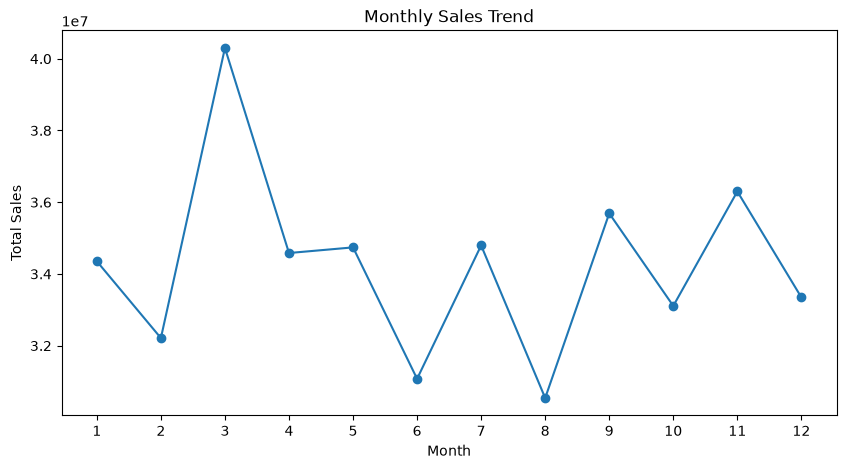

In [78]:
plt.figure(figsize=(10,5))

plt.plot(
    monthly_analysis["Month"],
    monthly_analysis["Total_Sales"],
    marker = 'o'
    )
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.title("Monthly Sales Trend")
plt.xticks(range(1,13))
plt.show()

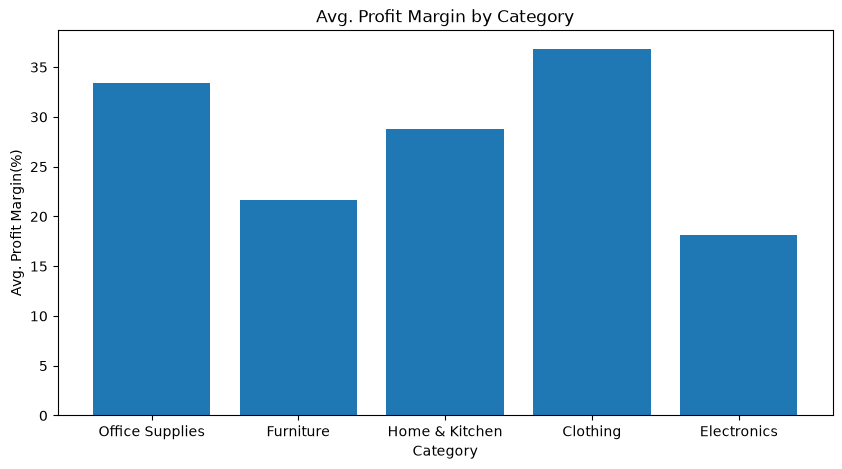

In [79]:
plt.figure(figsize=(10, 5))

plt.bar(
    category_analysis.index,
    category_analysis["Profit_Margin"]
)

plt.xlabel("Category")
plt.ylabel("Avg. Profit Margin(%)")
plt.title("Avg. Profit Margin by Category")
plt.show()

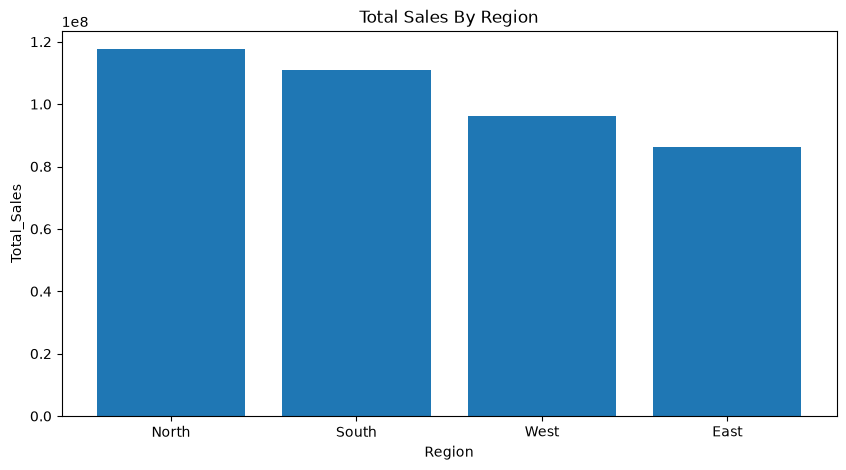

In [80]:
plt.figure(figsize=(10,5))

plt.bar(
regional_analysis.index,
regional_analysis["Total_Sales"]
)
    
plt.xlabel("Region")
plt.ylabel("Total_Sales")
plt.title("Total Sales By Region")
plt.show()